<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🧭 Deep Agents 知识地图（索引 + 自测）

**一句话定位**：6 份概念笔记的入口。Deep Agent = **ReAct 循环 + 三件武器（TODO 治忘 / Files 治挤 / Subagents 治乱）+ harness**。
> 建于 2026-10-20；主课 notebook 里的 🆕 格子与这里互相引用。

</div>

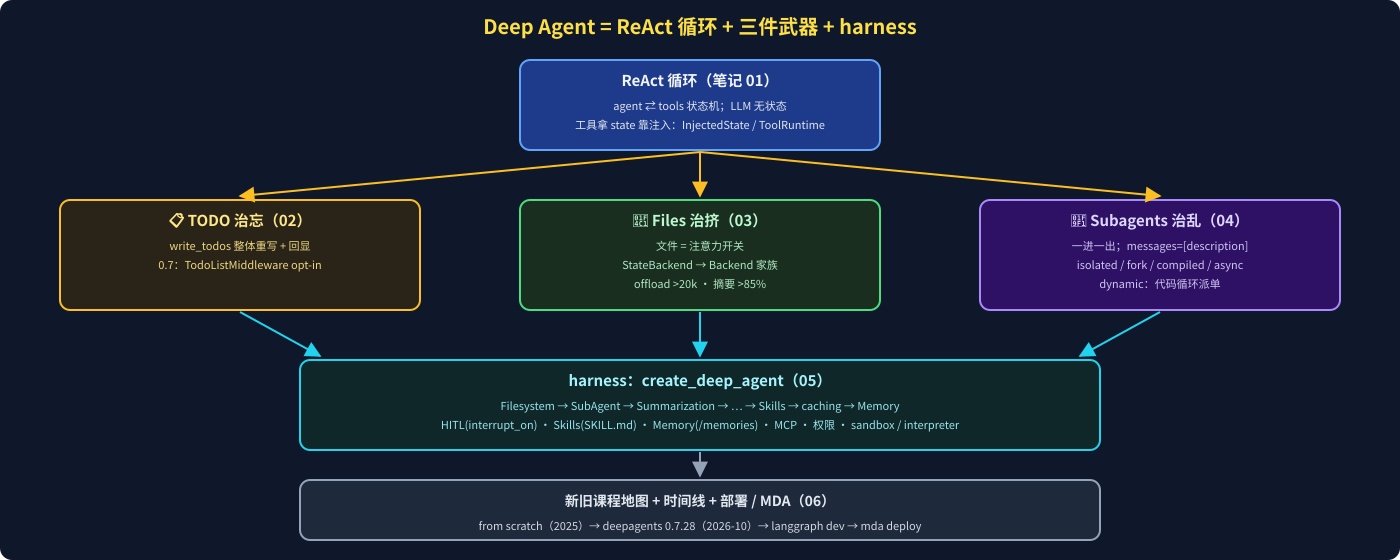

In [ ]:
from IPython.display import SVG
SVG(filename="assets/07_knowledge_map.svg")

### 📚 笔记索引

| # | 文件 | 一句话 | 对应主课 |
|---|---|---|---|
| 01 | `01_react_loop_state_injection.ipynb` | 循环在 graph 里；工具拿 state 靠注入（`InjectedState` → `ToolRuntime`）；`Command` ⇄ `ToolMessage` ⇄ `tool_call_id` 互为前提 | 0_a |
| 02 | `02_todo_recitation.ipynb` | recitation 治 context rot；`write_todos` = 整体重写 + 回显；0.7 起 opt-in | 1_a |
| 03 | `03_filesystem_backends.ipynb` | 文件 = 注意力开关；工具面固定 / Backend 可换；权限首个命中；自动 offload + 摘要；shell / sandbox / interpreter | 2_a |
| 04 | `04_subagents_delegation.ipynb` | 一进一出的隔离；库版 `task` 内部；isolated / fork / compiled / async；dynamic subagents | 3_a |
| 05 | `05_deepagents_harness.ipynb` | `create_deep_agent` 参数 + middleware 栈；HITL；skills；memory；MCP | 4_a |
| 06 | `06_new_course_map.ipynb` | 新旧课程对照、版本时间线、部署与 MDA、过时点速查 | 全部 |

主课 notebook（`../notebooks/`）：`N_a_🔥_*` 主课（含 🆕 2026-10 格子）· `N_b/c/d_⭐️_*` 深挖 · `N_z_⭐️_本节精华` 精华。

### 🔑 概念 → 去哪找

| 概念 | 笔记 |
|---|---|
| ReAct / ToolNode / 条件边 / recursion_limit | 01 |
| `InjectedState` `InjectedToolCallId` `ToolRuntime` `Command(update=)` | 01 |
| context rot / recitation / `TodoListMiddleware` | 02 |
| reducer（覆盖 vs merge、何时必需）/ `DeltaChannel` | 03 ② |
| `StateBackend` `FilesystemBackend` `CompositeBackend` `StoreBackend` `LocalShellBackend` `LangSmithSandbox` | 03 ④ |
| `FilesystemPermission` / `FilesystemMiddleware(tools=)` | 03 ⑤ |
| offloading（20k / 50k）/ `SummarizationMiddleware`（85%） | 03 ⑥ |
| `execute` / sandbox-as-a-tool / `CodeInterpreterMiddleware` / PTC | 03 ⑦ |
| context clash / confusion / poisoning / dilution | 04 ① |
| `SubAgent` 字段 / `task` 内部 / general-purpose / 递归拒绝 | 04 ② ③ |
| fork / `CompiledSubAgent` / `AsyncSubAgent` / `*_async_task` | 04 ④ |
| dynamic subagents | 04 ⑤ |
| `create_deep_agent` 参数 / middleware 顺序 / harness profile / prompt caching | 05 ① ② |
| thread / checkpointer / time travel | 05 ③（细讲：foundation 笔记 15） |
| HITL `interrupt_on` / approve edit reject respond | 05 ④ |
| SKILL.md / 渐进披露 / pinned_skills / include_tools | 05 ⑤ |
| `memory=` / `<agent_memory>` / namespace 范围 | 05 ⑥ |
| MCP transport / allowlist | 05 ⑦ |
| `langgraph dev` / Agent Server API / `mda` | 06 ④ |
| 版本时间线 / 过时点 | 06 ③ ⑥ |

### 🧪 自测（答不出就回对应笔记）

1. 为什么说「循环不在 LLM 里」？退出条件是什么？（01）
2. `tool_call_id` 为什么必须注入？漏掉 ToolMessage 会怎样？（01）
3. `ToolRuntime` 比 `InjectedState` 多给了什么？（01）
4. `todos` 为什么**不配** reducer？`read_todos` 给谁读？（02）
5. 0.7 为什么把 `write_todos` 移出默认？怎么加回来？（02）
6. 顺序写文件要不要 `file_reducer`？哪两个场景必需？（03）
7. `StateBackend` 的文件在 thread B 能读到吗？想跨 thread 用什么？（03）
8. 权限规则 `allow /**` 在前、`deny /secrets/**` 在后，`/secrets/key.txt` 可读吗？（03）
9. 工具结果 25k token 时模型看到什么？文件在哪？（03）
10. interpreter 和 `execute` 的区别？PTC 省了什么？（03）
11. 库版 `task` 的隔离一行是什么？回传时哪些 state key 会被丢弃？（04）
12. fork 模式子 agent 继承什么？什么时候用？（04）
13. sync 与 async 子 agent 的 4 点区别？async 启动后模型该做什么？（04）
14. 1000 份转录为什么不能让模型逐个 `task`？（04）
15. 不传 `system_prompt` 模型看到什么？默认 8 个工具是哪些？（05）
16. HITL 的四件套？`respond` 为什么不能拦 `send_email`？（05）
17. skill 和 memory 在「何时加载全文」上有什么不同？（05）
18. `("memory", user_id)` 和 `("memory", workspace_id, user_id)` 是同一份记忆吗？（05）
19. 本课 4_a 的 `create_deep_agent` 在 0.7.28 上要改哪 3 处？（06）
20. `langgraph dev` 提供了哪 4 类内置服务？`mda deploy` 和它的关系？（06）

### 🛣️ 复习路线

1. **01 → 02 → 03 → 04**：按三件武器的顺序，每篇先看 SVG 再看「坑」表。
2. **05**：把三件武器放回 `create_deep_agent` 的 middleware 栈里，再补 HITL / skills / memory / MCP。
3. **06**：确认哪些旧写法已变，顺便看部署路径。
4. 卡住就回主课 `N_a_🔥_*.ipynb` 对应 cell 旁的 🆕 格子，那里有本机实测输出。
5. 想动手：在 scratch 环境装 `deepagents==0.7.28`，用 `GenericFakeChatModel` 返回预设 `AIMessage(tool_calls=...)` 就能**不花钱**验证工具列表、`read_file` 格式、`write_todos`（本笔记系列的实测就是这么做的）。

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：Deep Agent = **ReAct 循环 + TODO 治忘 + Files 治挤 + Subagents 治乱**，外面包一层 **harness**（`create_deep_agent` 的 middleware 栈）；零件原理从本课到 deepagents 0.7.28 没变，变的只是 **TODO opt-in、`system_prompt` 键、`FileData`** 三处细节。

</div>